# **MASK VS NO MASK DETECTION**

In [ ]:
import os
import cv2
import numpy as np
from sklearn.cluster import KMeans
from sklearn.model_selection import train_test_split
from tensorflow.keras.utils import to_categorical
import tensorflow as tf
from tensorflow.keras.layers import Input, Dense, Dropout, Flatten, Conv2D, MaxPooling2D, concatenate
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import matplotlib.pyplot as plt
import random
from sklearn.preprocessing import StandardScaler

In [ ]:
data_dir = '/content/drive/MyDrive/CV_210649/PROJECT/dataset'
categories = ['with_mask', 'without_mask']

Initializing the SIFT detector

In [ ]:
sift = cv2.SIFT_create()

extracting sift features from image

In [ ]:
def extract_sift_features(image):
    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    keypoints, descriptors = sift.detectAndCompute(gray, None)
    if descriptors is None:
        return np.zeros((1, 128))
    return descriptors

Initializing lists to store data

In [ ]:
all_sift_features = []
data_images = []
data_sift = []
labels = []

loading the images and now feature extraction

In [ ]:
for category in categories:
    path = os.path.join(data_dir, category)
    class_num = categories.index(category)
    for img in os.listdir(path):
        try:
            img_array = cv2.imread(os.path.join(path, img), cv2.IMREAD_COLOR)
            resized_img = cv2.resize(img_array, (128, 128))
            sift_features = extract_sift_features(resized_img).astype('float32')
            if sift_features.shape[0] < 10:
                continue
            data_images.append(resized_img)
            data_sift.append(sift_features[:10].flatten())
            labels.append(class_num)
            all_sift_features.extend(sift_features)
        except Exception as e:
            pass

converting the lists to arrays

In [ ]:
data_images = np.array(data_images)
data_sift = np.array(data_sift)
labels = to_categorical(labels, num_classes=2)

  Creating Bag of Visual Words histogram for image

In [ ]:
num_clusters = 100
kmeans = KMeans(n_clusters=num_clusters, random_state=42, n_init=10)
kmeans.fit(np.array(all_sift_features))

def create_bovw_histogram(sift_descriptors, kmeans_model):
    visual_words = kmeans_model.predict(sift_descriptors)
    histogram = np.zeros(num_clusters)
    for word in visual_words:
        histogram[word] += 1
    return histogram

histogram creation for all images

In [ ]:
data_bovw = [create_bovw_histogram(sift_desc.reshape(-1, 128), kmeans) for sift_desc in data_sift]
data_bovw = np.array(data_bovw)

standardizing features

In [ ]:
scaler = StandardScaler()
data_sift = scaler.fit_transform(data_sift)
data_bovw = scaler.fit_transform(data_bovw)

train test splitting

In [ ]:
X_train_images, X_test_images, X_train_sift, X_test_sift, X_train_bovw, X_test_bovw, y_train, y_test = train_test_split(
    data_images, data_sift, data_bovw, labels, test_size=0.2, random_state=42)

CNN moedel for image processing

In [ ]:
cnn_input = Input(shape=(128, 128, 3))
cnn_output = Conv2D(32, (3, 3), activation='relu')(cnn_input)
cnn_output = MaxPooling2D((2, 2))(cnn_output)
cnn_output = Dropout(0.2)(cnn_output)
cnn_output = Conv2D(64, (3, 3), activation='relu')(cnn_output)
cnn_output = MaxPooling2D((2, 2))(cnn_output)
cnn_output = Dropout(0.2)(cnn_output)
cnn_output = Conv2D(128, (3, 3), activation='relu')(cnn_output)
cnn_output = MaxPooling2D((2, 2))(cnn_output)
cnn_output = Dropout(0.2)(cnn_output)
cnn_output = Conv2D(256, (3, 3), activation='relu')(cnn_output)
cnn_output = MaxPooling2D((2, 2))(cnn_output)
cnn_output = Dropout(0.2)(cnn_output)
cnn_output = Flatten()(cnn_output)
cnn_model = Model(cnn_input, cnn_output)

sift and bivw features for input layer

In [ ]:
sift_input = Input(shape=(1280,))
bovw_input = Input(shape=(num_clusters,))

concanetaing cnn + bovw + sift features

In [ ]:
combined_input = concatenate([cnn_model.output, sift_input, bovw_input])

fully connected layer for classification

In [ ]:
fc_output = Dense(128, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(combined_input)
fc_output = Dropout(0.5)(fc_output)
fc_output = Dense(64, activation='relu', kernel_regularizer=tf.keras.regularizers.l2(0.001))(fc_output)
fc_output = Dropout(0.5)(fc_output)
output = Dense(2, activation='softmax')(fc_output)

compiling model and callbacks for early stopping and learning rate reduction

In [ ]:
model = Model(inputs=[cnn_input, sift_input, bovw_input], outputs=output)
model.compile(optimizer=Adam(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

early_stopping = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.2, patience=2, min_lr=0.0001)

model training

In [ ]:
history = model.fit(
    [X_train_images, X_train_sift, X_train_bovw], y_train,
    validation_data=([X_test_images, X_test_sift, X_test_bovw], y_test),
    epochs=20,
    batch_size=32,
    callbacks=[early_stopping, reduce_lr]
)

Epoch 1/20
103/103 [==============================] - 149s 1s/step - loss: 3.9861 - accuracy: 0.6732 - val_loss: 0.7273 - val_accuracy: 0.8460 - lr: 0.0010
Epoch 2/20
103/103 [==============================] - 144s 1s/step - loss: 0.7134 - accuracy: 0.8288 - val_loss: 0.7484 - val_accuracy: 0.7946 - lr: 0.0010
Epoch 3/20
103/103 [==============================] - 144s 1s/step - loss: 0.6384 - accuracy: 0.8658 - val_loss: 0.6755 - val_accuracy: 0.8521 - lr: 0.0010
Epoch 4/20
103/103 [==============================] - 145s 1s/step - loss: 0.5945 - accuracy: 0.8896 - val_loss: 0.6366 - val_accuracy: 0.8619 - lr: 0.0010
Epoch 5/20
103/103 [==============================] - 145s 1s/step - loss: 0.5391 - accuracy: 0.9138 - val_loss: 0.5899 - val_accuracy: 0.8875 - lr: 0.0010
Epoch 6/20
103/103 [==============================] - 144s 1s/step - loss: 0.4858 - accuracy: 0.9294 - val_loss: 0.5865 - val_accuracy: 0.8790 - lr: 0.0010
Epoch 7/20
103/103 [==============================] - 144s 1s/st

model evaluation

In [ ]:
loss, accuracy = model.evaluate([X_test_images, X_test_sift, X_test_bovw], y_test)
print(f'Loss: {loss}, Accuracy: {accuracy}')

26/26 [==============================] - 9s 362ms/step - loss: 0.4313 - accuracy: 0.9340
Loss: 0.43125173449516296, Accuracy: 0.9339853525161743


plotting the training history

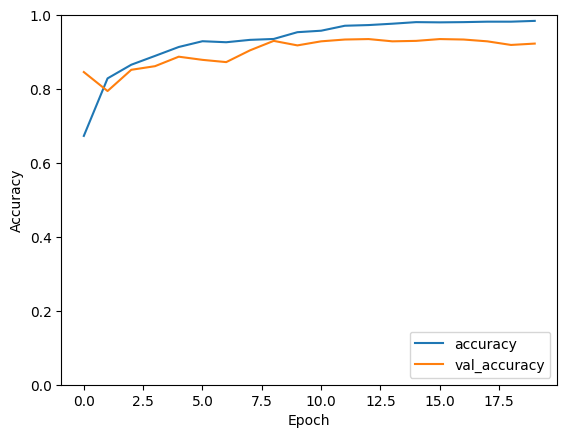

In [ ]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['val_accuracy'], label='val_accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.ylim([0, 1])
plt.legend(loc='lower right')
plt.show()

displaying actual and predicted predictions

26/26 [==============================] - 8s 293ms/step


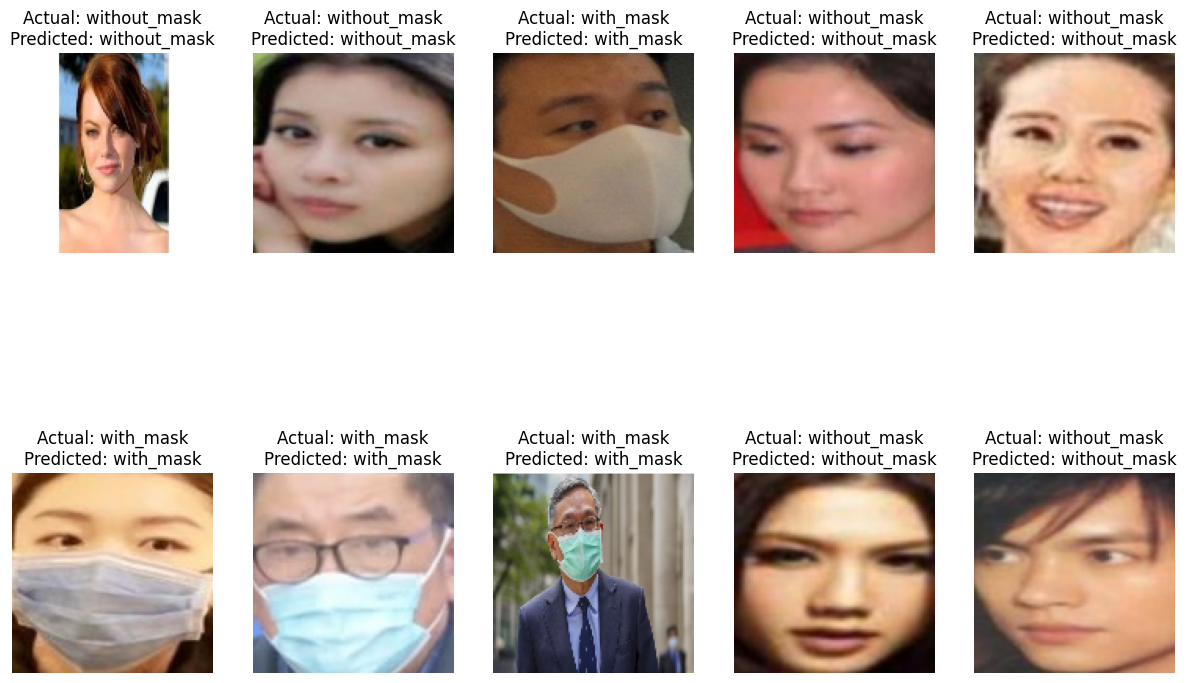

In [ ]:
def display_predictions(images, sift_features, bovw_features, labels, predictions, categories, num_samples=10):
    """Display random sample of test images with their predicted and actual labels."""
    indices = random.sample(range(len(images)), num_samples)
    plt.figure(figsize=(15, 10))
    for i, idx in enumerate(indices):
        plt.subplot(2, num_samples // 2, i + 1)
        plt.imshow(cv2.cvtColor(images[idx], cv2.COLOR_BGR2RGB))
        actual_label = categories[np.argmax(labels[idx])]
        predicted_label = categories[np.argmax(predictions[idx])]
        plt.title(f"Actual: {actual_label}\nPredicted: {predicted_label}")
        plt.axis('off')
    plt.show()

predictions = model.predict([X_test_images, X_test_sift, X_test_bovw])
display_predictions(X_test_images, X_test_sift, X_test_bovw, y_test, predictions, categories, num_samples=10)